# Tree Species Classification Using Deep Learning

**Course:** Neural Networks — 2026

**Group members:**

Timofey Krylov (timofey.krylov@student.hamk.fi)

Tomi Kitola (tomi.kitola@student.hamk.fi)

Jaakko Ruhanen (jaakko.ruhanen@student.hamk.fi)



## Project Overview

This project focuses on classifying urban tree species using pretrained convolutional neural networks (CNNs).

Two models, ResNet18 and ResNet50, are trained and compared using the same dataset.

The project covers image preprocessing, data augmentation, transfer learning, model evaluation, error analysis, and model improvement.

**Dataset:** [Tree Dataset of Urban Street](https://www.kaggle.com/datasets/erickendric/tree-dataset-of-urban-street-classification-tree)

### Requirements & Installation

Before running the notebook, install the required Python libraries in your environment.

```bash
python -m pip install numpy torch torchvision Pillow matplotlib seaborn pandas scikit-learn kagglehub ipykernel
```

The libraries only need to be installed once per environment.

Note: GPU acceleration may require a separate PyTorch installation.

## 0. Environment Setup

In [45]:
#  imports
import os, random, time, copy
import numpy as np
import torch, torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
from torch.utils.data import DataLoader
import torchvision
from torchvision import models, transforms as T
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_recall_fscore_support, classification_report)

from tree_data import TreeDataset   # in a .py file so DataLoader workers work on Windows

plt.rcParams["figure.dpi"] = 90

# Reproducibility
SEED = 72
torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)

# RTX 4070
device = torch.device("cuda")
torch.backends.cudnn.benchmark = True        # fastest conv algorithms for fixed input size
torch.set_float32_matmul_precision("high")   # TF32 for remaining fp32 math
AMP_DTYPE = torch.bfloat16                   # mixed precision -> tensor cores

NUM_WORKERS = 8   # parallel image loading

SAVE_DIR = "models"
os.makedirs(SAVE_DIR, exist_ok=True)

print("Device:", torch.cuda.get_device_name(0))

Device: NVIDIA GeForce RTX 4070 Laptop GPU


## 1. Dataset: Tree Dataset of Urban Street

The dataset contains images of urban street trees collected across 10 cities and different seasons.

Images are organized by species, with folder names used as class labels.

The dataset comes with its own stratified split into training (80%), validation (10%) and test (10%) sets, which we use as is.

In [46]:
# Download the dataset from Kaggle

import kagglehub

path = kagglehub.dataset_download("erickendric/tree-dataset-of-urban-street-classification-tree")
print("Dataset folder:", path)

Dataset folder: C:\Users\jaakk\.cache\kagglehub\datasets\erickendric\tree-dataset-of-urban-street-classification-tree\versions\1


In [47]:
# Inspect the dataset folder structure
for root, dirs, files in os.walk(path):
    depth = root[len(path):].count(os.sep)
    if depth <= 2:
        print("    " * depth + os.path.basename(root) + f"/  ({len(files)} files)")

1/  (0 files)
    tree/  (0 files)
        test/  (0 files)
        train/  (0 files)
        val/  (0 files)


In [48]:
# Collect image paths and assign species labels using folder names.
# Use unique (species, filename) keys to avoid duplicate entries.
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp")

images = {}
for root, dirs, files in os.walk(path):
    for f in files:
        if f.lower().endswith(IMG_EXT):
            images[(os.path.basename(root), f)] = os.path.join(root, f)

all_species = [k[0] for k in images]
all_paths   = list(images.values())
class_names = sorted(set(all_species))
num_classes = len(class_names)

print("Images:", len(all_paths), "| Classes:", num_classes)
print(class_names)

Images: 4804 | Classes: 23
['Acer palmatum', 'Cedrus deodara', 'Celtis sinensis', 'Cinnamomum camphora (Linn) Presl', 'Elaeocarpus decipiens', 'Flowering cherry', 'Ginkgo biloba', 'Koelreuteria paniculata', 'Lagerstroemia indica', 'Liquidambar formosana', 'Liriodendron chinense', 'Magnolia grandiflora L', 'Magnolia liliflora Desr', 'Michelia chapensis', 'Osmanthus fragrans', 'Photinia serratifolia', 'Platanus', 'Prunus cerasifera f. atropurpurea', 'Salix babylonica', 'Sapindus saponaria', 'Styphnolobium japonicum', 'Triadica sebifera', 'Zelkova serrata']


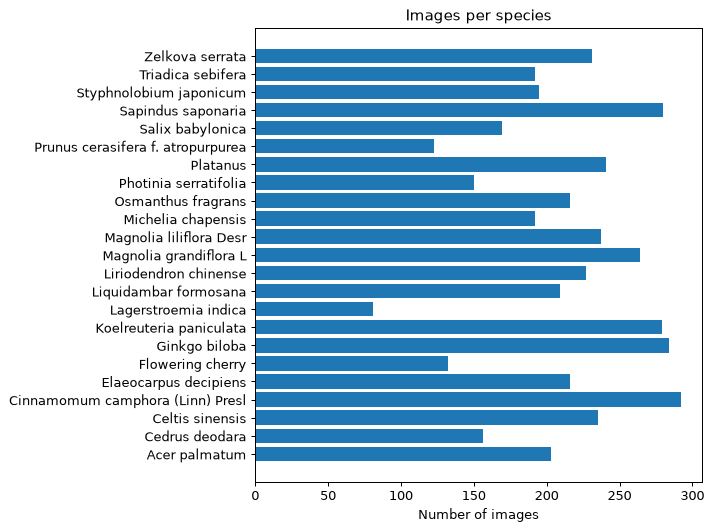

Smallest class: Lagerstroemia indica 81 | Biggest class: Cinnamomum camphora (Linn) Presl 292


In [49]:
# Visualize the number of images per species
counts = pd.Series(all_species).value_counts().sort_index()

plt.figure(figsize=(8, 6))
plt.barh(counts.index, counts.values)
plt.xlabel("Number of images"); plt.title("Images per species")
plt.tight_layout(); plt.show()

print("Smallest class:", counts.idxmin(), counts.min(), "| Biggest class:", counts.idxmax(), counts.max())

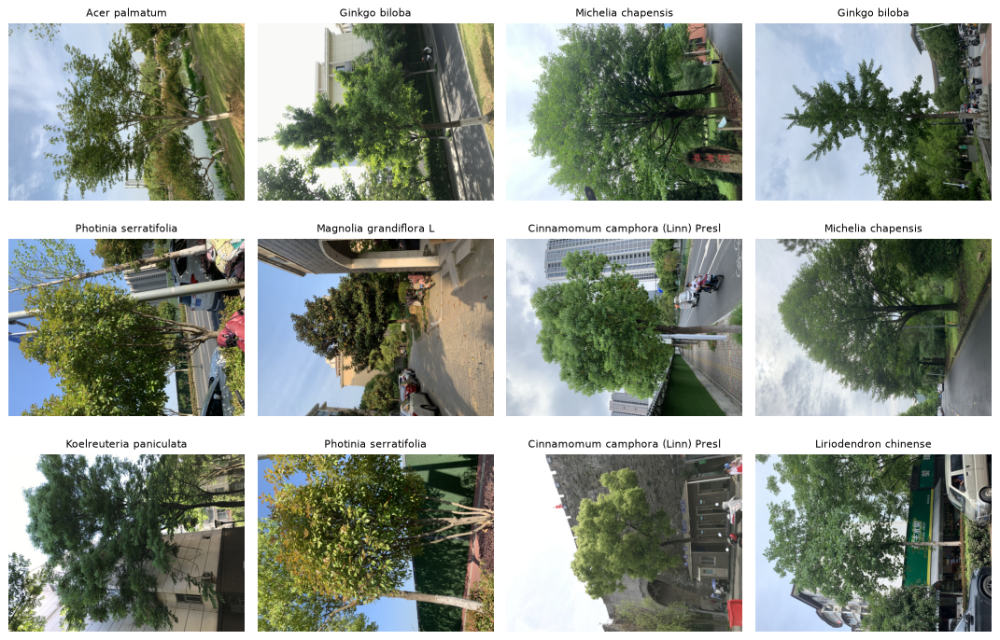

In [50]:
# Display random samples from the dataset
fig, axs = plt.subplots(3, 4, figsize=(12, 8))
for ax, i in zip(axs.ravel(), random.sample(range(len(all_paths)), 12)):
    ax.imshow(ImageOps.exif_transpose(Image.open(all_paths[i])))
    ax.set_title(all_species[i], fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

## 2. Pixels & Image Tensors

**Key ideas**
- Tree images use **RGB** with 3 color channels
- PIL/NumPy format: `(H, W, 3)`
- PyTorch tensor format: `(3, H, W)`
- Image size affects memory usage and training speed

In [51]:
# Inspect one tree image
img = ImageOps.exif_transpose(Image.open(all_paths[0])).convert("RGB")
x = T.ToTensor()(img)

print("PIL size (W, H):", img.size)
print("Tensor shape:", x.shape)
print("Data type:", x.dtype)
print("Min/Max:", float(x.min()), float(x.max()))

# Compare input sizes
print("Flattened RGB 224x224:", 3 * 224 * 224)
print("Flattened MNIST 28x28:", 28 * 28)

# Check original image sizes
sizes = [Image.open(p).size for p in random.sample(all_paths, 50)]

print("Examples:", sizes[:8])
print("Width range:", min(s[0] for s in sizes), "-", max(s[0] for s in sizes))
print("Height range:", min(s[1] for s in sizes), "-", max(s[1] for s in sizes))

PIL size (W, H): (1600, 1200)
Tensor shape: torch.Size([3, 1200, 1600])
Data type: torch.float32
Min/Max: 0.0 1.0
Flattened RGB 224x224: 150528
Flattened MNIST 28x28: 784
Examples: [(1600, 1200), (1600, 1200), (1600, 1200), (1600, 1200), (1600, 1200), (1600, 1200), (1271, 1600), (1600, 1200)]
Width range: 1199 - 1600
Height range: 1200 - 1600


## 3. What is Image Classification?

**Key ideas**
- Input: RGB image tensor `[3, 224, 224]`
- Output: one of **23 tree species**
- Model predicts **23 logits**, one for each class
- Loss function: **CrossEntropyLoss**
- Evaluation: **Accuracy, Precision, Recall, F1-score**
- Additional evaluation: **Confusion Matrix and Top-N Accuracy**

## 4. Image Preprocessing & Dataset Split

**Key ideas**
- Resize images to 256 pixels while keeping aspect ratio
- Convert images to RGB
- Skip broken images
- Use the dataset's own split: 80% Train, 10% Validation, 10% Test
- The provided split is already stratified (every species ≈ 80 / 10 / 10)

In [52]:
# Resize and save images
SMALL_DIR = "data_small"
shrink = T.Resize(256)

paths, species, splits = [], [], []
start = time.time()

for i, (p, sp) in enumerate(zip(all_paths, all_species)):
    out_dir = os.path.join(SMALL_DIR, sp)
    os.makedirs(out_dir, exist_ok=True)

    out_path = os.path.join(out_dir, f"{i}.jpg")

    if not os.path.exists(out_path):
        try:
            im = ImageOps.exif_transpose(Image.open(p)).convert("RGB")
            shrink(im).save(out_path, quality=95)
        except Exception as e:
            print("Skipped broken image:", p, e)
            continue

    paths.append(out_path)
    species.append(sp)
    splits.append(os.path.basename(os.path.dirname(os.path.dirname(p))))   # tree/<split>/<species>/file

print(f"{len(paths)} images ready in {time.time() - start:.0f} s")


# Use the train / val / test split that comes with the dataset (80 / 10 / 10, stratified)
labels = [class_names.index(s) for s in species]

def pick(name):
    idx = [i for i, s in enumerate(splits) if s == name]
    return [paths[i] for i in idx], [labels[i] for i in idx]

train_p, train_y = pick("train")
val_p, val_y = pick("val")
test_p, test_y = pick("test")

print("Train:", len(train_p))
print("Validation:", len(val_p))
print("Test:", len(test_p))

4804 images ready in 1 s
Train: 3850
Validation: 482
Test: 472


## 5. Transforms & Augmentation
**Why transforms?**
- Put images into the right format/range (`ToTensor`).
- Standardize scale per channel (`Normalize`) — here with **ImageNet mean/std**, because the pretrained
  ResNet weights were trained with those values (so we don't need `compute_mean_std` like with MNIST).
- Ensure common sizes for batching (`Resize` / `CenterCrop` / `RandomResizedCrop`).
- Increase diversity with randomness (augmentations) → less overfitting.

### Visualization Resize and Augmentation

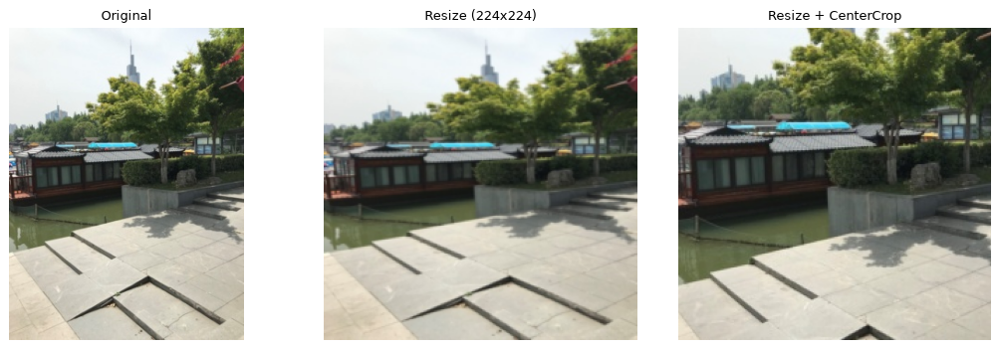

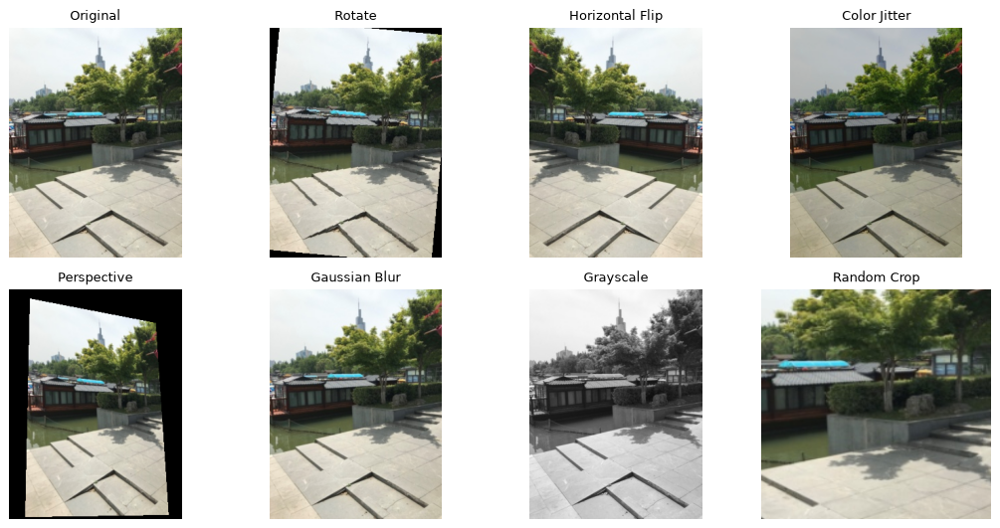

In [53]:
# Load sample image
img = Image.open(train_p[0]).convert("RGB")

# Compare resizing methods
variants = [
    ("Original", img),
    ("Resize (224x224)", T.Resize((224, 224))(img)),
    ("Resize + CenterCrop", T.Compose([
        T.Resize(256), T.CenterCrop(224)
    ])(img))
]

fig, axs = plt.subplots(1, 3, figsize=(12, 4))

for ax, (name, im) in zip(axs, variants):
    ax.imshow(im)
    ax.set_title(name, fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.show()


# Compare data augmentations
augs = [
    ("Rotate", T.RandomRotation(15)),
    ("Horizontal Flip", T.RandomHorizontalFlip(p=1.0)),
    ("Color Jitter", T.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.4, hue=0.1)),
    ("Perspective", T.RandomPerspective(distortion_scale=0.4, p=1.0)),
    ("Gaussian Blur", T.GaussianBlur(kernel_size=9, sigma=(0.1, 2.0))),
    ("Grayscale", T.RandomGrayscale(p=1.0)),
    ("Random Crop", T.RandomResizedCrop(224))
]

fig, axs = plt.subplots(2, 4, figsize=(12, 6))
axs = axs.ravel()

axs[0].imshow(img)
axs[0].set_title("Original", fontsize=10)
axs[0].axis("off")

for i, (name, aug) in enumerate(augs, start=1):
    axs[i].imshow(aug(img))
    axs[i].set_title(name, fontsize=10)
    axs[i].axis("off")

plt.tight_layout()
plt.show()

### Transform Recipes — Round 1

- Training: RandomResizedCrop and RandomHorizontalFlip
- Validation and Test: Resize and CenterCrop
- All images are converted to tensors and normalized using ImageNet values
- Random augmentations are applied only to training images

In [54]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_tfms = T.Compose([
    T.RandomResizedCrop(224),          # random part of the image, resized to 224x224
    T.RandomHorizontalFlip(),          # trees look the same mirrored
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

val_tfms = T.Compose([
    T.Resize(256),
    T.CenterCrop(224),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

train_tfms, val_tfms

(Compose(
     RandomResizedCrop(size=(224, 224), scale=(0.08, 1.0), ratio=(0.75, 1.3333), interpolation=bilinear, antialias=True)
     RandomHorizontalFlip(p=0.5)
     ToTensor()
     Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
 ),
 Compose(
     Resize(size=256, interpolation=bilinear, max_size=None, antialias=True)
     CenterCrop(size=(224, 224))
     ToTensor()
     Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
 ))

### Dataset & DataLoaders

In [55]:
def make_loaders(train_transform, batch_size=32):
    def loader(paths, labels, tfms, bs, shuffle, workers):
        return DataLoader(TreeDataset(paths, labels, tfms), batch_size=bs, shuffle=shuffle, num_workers=workers, pin_memory=True, persistent_workers=True, prefetch_factor=4)
    
    return {
        "train": loader(train_p, train_y, train_transform, batch_size, True, NUM_WORKERS),
        "val":   loader(val_p, val_y, val_tfms, 256, False, 2),
        "test":  loader(test_p, test_y, val_tfms, 256, False, 2),
    }


loaders = make_loaders(train_tfms)

xb, yb = next(iter(loaders["train"]))
print(xb.shape, yb.shape)

torch.Size([32, 3, 224, 224]) torch.Size([32])


## 6. Modeling: Pretrained ResNets

**Models**
| | ResNet18 | ResNet50 |
|---|---|---|
| Layers | 18 | 50 |
| Parameters | ~11.7M | ~25.6M |
| Features | 512 | 2048 |
| ImageNet Accuracy | 69.8% | 76.1% |

**Transfer Learning**
- Both models use pretrained ImageNet weights
- The final layer is replaced to predict **23 tree species**
- All layers are trained using a small learning rate
- We compare accuracy and training performance

In [56]:
def make_model(name, num_classes=num_classes):
    if name == "resnet18":
        model = models.resnet18(weights="IMAGENET1K_V1")
    elif name == "resnet50":
        model = models.resnet50(weights="IMAGENET1K_V1")
    else:
        raise ValueError(name)

    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model.to(device, memory_format=torch.channels_last)


def count_params(model):
    return sum(p.numel() for p in model.parameters())


for name in ["resnet18", "resnet50"]:
    m = make_model(name)
    print(f"{name}: {count_params(m)/1e6:.1f} M parameters | last layer: {m.fc}")

del m

resnet18: 11.2 M parameters | last layer: Linear(in_features=512, out_features=23, bias=True)
resnet50: 23.6 M parameters | last layer: Linear(in_features=2048, out_features=23, bias=True)


### Training & Evaluation Helpers

**Key ideas**
- Train models and track loss and accuracy
- Use `CrossEntropyLoss`, Adam and StepLR
- Save the best model based on validation accuracy
- Evaluate models using Accuracy, Precision, Recall and F1
- Visualize learning curves, confusion matrices and prediction errors
- Calculate Top-N Accuracy

In [57]:
# ---------------- Training helpers ----------------

def denorm(x, mean=IMAGENET_MEAN, std=IMAGENET_STD):
    # Undo ImageNet normalization for display; x has shape [H, W, 3]
    return (x * torch.tensor(std) + torch.tensor(mean)).clamp(0, 1)


def show_batch(loader, n=16, nrow=8):
    # Show a batch of sample images from a DataLoader (after transforms/augmentation)
    xb, yb = next(iter(loader))
    grid = torchvision.utils.make_grid(xb[:n], nrow=nrow, padding=2)
    plt.figure(figsize=(14, 4))
    plt.imshow(denorm(grid.permute(1, 2, 0)))
    plt.axis("off"); plt.title("Sample training batch"); plt.show()
    print("Labels:", [class_names[i] for i in yb[:n]])


def evaluate_loader(model, loader, loss_fn, device=device):
    # Average loss and accuracy over a loader
    model.eval()
    with torch.inference_mode(), torch.autocast("cuda", dtype=AMP_DTYPE):
        running = torch.zeros((), device=device)
        correct = torch.zeros((), device=device, dtype=torch.long)
        for xb, yb in loader:
            xb = xb.to(device, non_blocking=True, memory_format=torch.channels_last)
            yb = yb.to(device, non_blocking=True)
            out = model(xb)
            running += loss_fn(out, yb) * xb.size(0)
            correct += (out.argmax(dim=1) == yb).sum()
    n = len(loader.dataset)
    return running.item() / n, correct.item() / n


def train_epochs(model, train_loader, val_loader, epochs=15, lr=1e-4, wd=1e-4, step_size=7, label_smoothing=0.0, device=device):
    # Train a model for multiple epochs, with validation at each epoch.
    # Returns the model with the BEST validation weights + history dictionary.
    ce = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
    opt = optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    sched = lr_scheduler.StepLR(opt, step_size=step_size, gamma=0.1) # from the transfer learning tutorial
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_acc, best_wts = 0.0, copy.deepcopy(model.state_dict())
    start = time.time()

    for ep in range(1, epochs + 1):
        model.train()
        running = torch.zeros((), device=device)
        correct = torch.zeros((), device=device, dtype=torch.long)

        # Training loop
        for xb, yb in train_loader:
            xb = xb.to(device, non_blocking=True, memory_format=torch.channels_last)
            yb = yb.to(device, non_blocking=True)
            with torch.autocast("cuda", dtype=AMP_DTYPE):
                out = model(xb)
                loss = ce(out, yb)

            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()

            running += loss.detach() * xb.size(0)   # stays on GPU, no sync every step
            correct += (out.argmax(1) == yb).sum()
        sched.step()

        train_loss = running.item() / len(train_loader.dataset)
        train_acc = correct.item() / len(train_loader.dataset)
        val_loss, val_acc = evaluate_loader(model, val_loader, ce, device)

        hist["train_loss"].append(train_loss); hist["train_acc"].append(train_acc)
        hist["val_loss"].append(val_loss);     hist["val_acc"].append(val_acc)

        mark = ""
        if val_acc > best_acc:   # keep the best epoch
            best_acc, best_wts, mark = val_acc, copy.deepcopy(model.state_dict()), "  *best*"
        print(f"Epoch {ep:2d} | train={train_loss:.4f} acc={train_acc:.4f} | "
              f"val={val_loss:.4f} acc={val_acc:.4f}{mark}")

    print(f"Training time: {(time.time() - start) / 60:.1f} min | best val acc: {best_acc:.4f}")
    model.load_state_dict(best_wts)
    return model, hist


def plot_curves(hist, title=""):
    # Loss and accuracy curves for train and validation
    epochs = range(1, len(hist["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
    ax1.plot(epochs, hist["train_loss"], label="train_loss")
    ax1.plot(epochs, hist["val_loss"], label="val_loss")
    ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss"); ax1.set_title(title + " loss")
    ax1.legend(); ax1.grid(True, alpha=0.3)
    ax2.plot(epochs, hist["train_acc"], label="train_acc")
    ax2.plot(epochs, hist["val_acc"], label="val_acc")
    ax2.set_xlabel("Epoch"); ax2.set_ylabel("Accuracy"); ax2.set_ylim(0, 1); ax2.set_title(title + " accuracy")
    ax2.legend(); ax2.grid(True, alpha=0.3)
    plt.tight_layout(); plt.show()

In [58]:
# ---------------- Evaluation helpers ----------------

def get_predictions(model, loader, device=device):
    # True labels, predicted labels and softmax probabilities (probabilities are needed for n-best)
    model.eval(); ys, probs = [], []
    with torch.inference_mode():   # fp32 here: exact probabilities for the final test results
        for xb, yb in loader:
            out = model(xb.to(device, non_blocking=True, memory_format=torch.channels_last))
            probs.append(torch.softmax(out.float(), dim=1).cpu())
            ys.append(yb)
    probs = torch.cat(probs).numpy()
    y_true = torch.cat(ys).numpy()
    return y_true, probs.argmax(1), probs


results = {}   # test results of every model, used for the comparisons

def test_model(model, name, loader):
    # Accuracy + macro precision / recall / F1 on the test set, stored in `results`
    y_true, y_pred, probs = get_predictions(model, loader, device)
    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    results[name] = dict(y_true=y_true, y_pred=y_pred, probs=probs,
                         accuracy=acc, precision=prec, recall=rec, f1=f1)
    print(f"{name:12s} | accuracy {acc:.4f} | precision {prec:.4f} | recall {rec:.4f} | F1 {f1:.4f}")


def show_confusion_matrices(name, labels=class_names, min_pct_annot=0.05, hide_diag_on_norm=False):
    # show_confusion_matrices is made bigger for 23 classes
    y_true, y_pred = results[name]["y_true"], results[name]["y_pred"]
    n = len(labels)
    cm_raw  = confusion_matrix(y_true, y_pred, labels=range(n))
    cm_norm = confusion_matrix(y_true, y_pred, labels=range(n), normalize="true")

    fig, axes = plt.subplots(1, 2, figsize=(24, 10))

    ann_raw = np.where(cm_raw == 0, "", cm_raw.astype(int))  # hide zeros
    sns.heatmap(cm_raw, ax=axes[0], annot=ann_raw, fmt="", cmap="Blues", cbar=False, square=True,
                linewidths=.5, linecolor="white", annot_kws={"size": 7},
                xticklabels=labels, yticklabels=labels)
    axes[0].set_title(f"{name} — confusion matrix (counts)")

    ann_norm = np.where(cm_norm >= min_pct_annot, np.round(cm_norm * 100).astype(int).astype(str), "")
    mask = np.eye(n, dtype=bool) if hide_diag_on_norm else None
    sns.heatmap(cm_norm, ax=axes[1], annot=ann_norm, fmt="", cmap="Blues", vmin=0, vmax=1, square=True,
                linewidths=.5, linecolor="white", mask=mask, annot_kws={"size": 7},
                xticklabels=labels, yticklabels=labels)
    axes[1].set_title(f"{name} — normalized % (≥{int(min_pct_annot*100)}% annotated)")

    for ax in axes:
        ax.set_xlabel("Pred"); ax.set_ylabel("True")
        ax.tick_params(axis="x", labelrotation=90, labelsize=8)
        ax.tick_params(axis="y", labelrotation=0, labelsize=8)
    plt.tight_layout(); plt.show()


def most_confused(name, top=10):
    # The most common (true -> predicted) mistakes
    cm = confusion_matrix(results[name]["y_true"], results[name]["y_pred"], labels=range(num_classes))
    np.fill_diagonal(cm, 0)
    pairs = [(cm[i, j], class_names[i], class_names[j])
             for i in range(num_classes) for j in range(num_classes) if cm[i, j] > 0]
    pairs.sort(reverse=True)
    print(f"--- {name}: most common errors (true → predicted) ---")
    for c, t, p in pairs[:top]:
        print(f"{c:3d}   {t}  →  {p}")


def show_misclassified(name, k=20, nrow=5):
    # Grid of k random wrong test predictions (original resized photo, true / predicted + confidence)
    r = results[name]
    wrong = np.where(r["y_true"] != r["y_pred"])[0]
    print(f"{name}: {len(wrong)} wrong out of {len(r['y_true'])} test images")
    pick = random.sample(list(wrong), min(k, len(wrong)))
    fig, axs = plt.subplots((len(pick) + nrow - 1) // nrow, nrow, figsize=(16, 3.6 * ((len(pick) + nrow - 1) // nrow)))
    for ax in np.atleast_1d(axs).ravel():
        ax.axis("off")
    for ax, i in zip(np.atleast_1d(axs).ravel(), pick):
        ax.imshow(Image.open(test_p[i]))
        ax.set_title(f"T: {class_names[r['y_true'][i]]}\nP: {class_names[r['y_pred'][i]]} ({r['probs'][i].max():.2f})",
                     fontsize=8, color="red")
    plt.tight_layout(); plt.show()


def top_n_accuracy(probs, y_true, n):
    # Correct if the true class is among the n highest probabilities
    top_n = np.argsort(probs, axis=1)[:, -n:]
    return np.mean([y_true[i] in top_n[i] for i in range(len(y_true))])

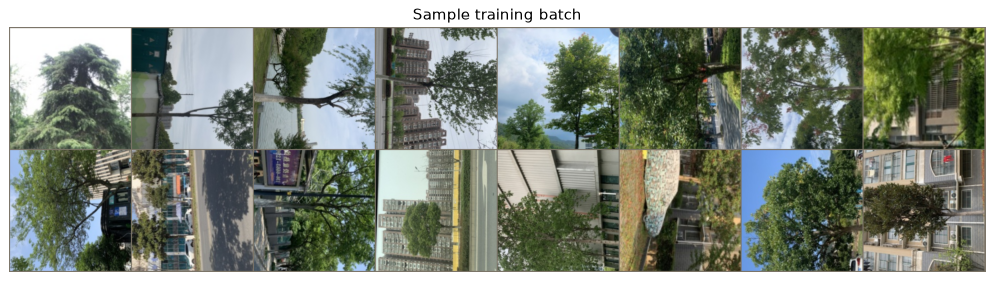

Labels: ['Cedrus deodara', 'Styphnolobium japonicum', 'Salix babylonica', 'Platanus', 'Liquidambar formosana', 'Photinia serratifolia', 'Koelreuteria paniculata', 'Koelreuteria paniculata', 'Celtis sinensis', 'Magnolia grandiflora L', 'Celtis sinensis', 'Cinnamomum camphora (Linn) Presl', 'Liriodendron chinense', 'Elaeocarpus decipiens', 'Elaeocarpus decipiens', 'Magnolia grandiflora L']


In [59]:
# Quick sanity check: visualize a batch of training images (after augmentation)
show_batch(loaders["train"])

## 7a. Cleaned images (no augmentation)
- Resize shorter side to 256 (aspect ratio kept) + CenterCrop 224 — same as val/test
- Every epoch sees exactly the same images
- Same train/val/test split and test pipeline as the augmented run → only difference is augmentation

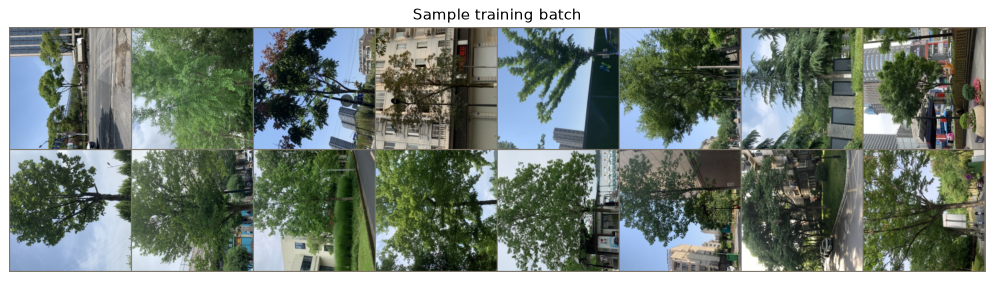

Labels: ['Cinnamomum camphora (Linn) Presl', 'Ginkgo biloba', 'Koelreuteria paniculata', 'Elaeocarpus decipiens', 'Zelkova serrata', 'Celtis sinensis', 'Cedrus deodara', 'Zelkova serrata', 'Platanus', 'Michelia chapensis', 'Liriodendron chinense', 'Liquidambar formosana', 'Triadica sebifera', 'Liriodendron chinense', 'Koelreuteria paniculata', 'Koelreuteria paniculata']


In [60]:
loaders_clean = {**loaders, "train": make_loaders(val_tfms)["train"]}   # val/test are the same loaders as the augmented run
show_batch(loaders_clean["train"])

Epoch  1 | train=1.5557 acc=0.5992 | val=0.6702 acc=0.8091  *best*
Epoch  2 | train=0.3349 acc=0.9340 | val=0.4004 acc=0.8921  *best*
Epoch  3 | train=0.0878 acc=0.9945 | val=0.2894 acc=0.9170  *best*
Epoch  4 | train=0.0346 acc=0.9992 | val=0.2863 acc=0.9149
Epoch  5 | train=0.0175 acc=1.0000 | val=0.2510 acc=0.9212  *best*
Epoch  6 | train=0.0121 acc=0.9997 | val=0.2707 acc=0.9212
Epoch  7 | train=0.0110 acc=0.9997 | val=0.2877 acc=0.9108
Epoch  8 | train=0.0092 acc=0.9997 | val=0.2581 acc=0.9170
Epoch  9 | train=0.0085 acc=0.9995 | val=0.2522 acc=0.9232  *best*
Epoch 10 | train=0.0065 acc=1.0000 | val=0.2528 acc=0.9212
Epoch 11 | train=0.0066 acc=1.0000 | val=0.2479 acc=0.9212
Epoch 12 | train=0.0064 acc=1.0000 | val=0.2459 acc=0.9232
Epoch 13 | train=0.0061 acc=1.0000 | val=0.2449 acc=0.9232
Epoch 14 | train=0.0055 acc=1.0000 | val=0.2404 acc=0.9232
Epoch 15 | train=0.0052 acc=1.0000 | val=0.2384 acc=0.9253  *best*
Training time: 1.3 min | best val acc: 0.9253


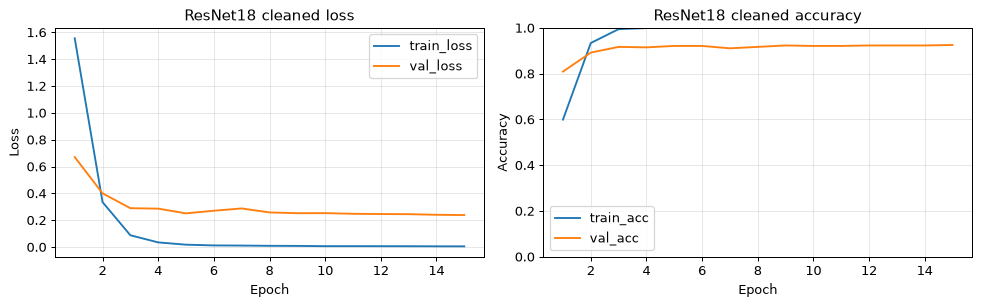

Epoch  1 | train=1.4008 acc=0.6278 | val=0.4869 acc=0.8714  *best*
Epoch  2 | train=0.2565 acc=0.9364 | val=0.2910 acc=0.9046  *best*
Epoch  3 | train=0.0984 acc=0.9787 | val=0.2654 acc=0.9253  *best*
Epoch  4 | train=0.0604 acc=0.9870 | val=0.2873 acc=0.8983
Epoch  5 | train=0.0683 acc=0.9823 | val=0.3328 acc=0.8900
Epoch  6 | train=0.0568 acc=0.9865 | val=0.2865 acc=0.9087
Epoch  7 | train=0.0477 acc=0.9875 | val=0.2589 acc=0.9129
Epoch  8 | train=0.0248 acc=0.9951 | val=0.2069 acc=0.9336  *best*
Epoch  9 | train=0.0102 acc=0.9990 | val=0.2047 acc=0.9315
Epoch 10 | train=0.0074 acc=0.9997 | val=0.1942 acc=0.9315
Epoch 11 | train=0.0074 acc=0.9997 | val=0.1993 acc=0.9295
Epoch 12 | train=0.0070 acc=0.9995 | val=0.1957 acc=0.9336
Epoch 13 | train=0.0051 acc=1.0000 | val=0.1969 acc=0.9295
Epoch 14 | train=0.0045 acc=1.0000 | val=0.1871 acc=0.9378  *best*
Epoch 15 | train=0.0055 acc=0.9997 | val=0.1961 acc=0.9378
Training time: 3.1 min | best val acc: 0.9378


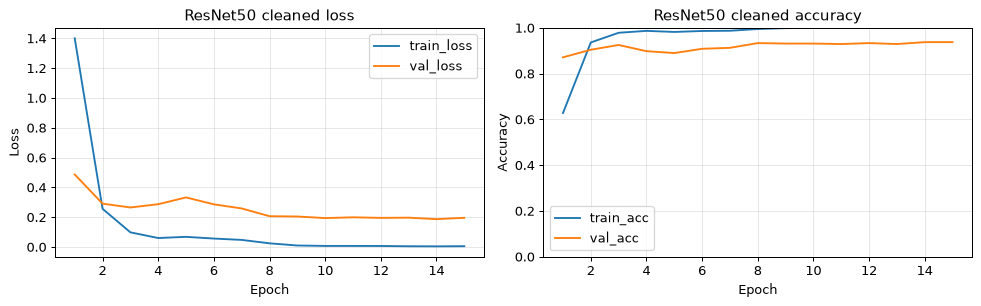

In [61]:
EPOCHS = 15

model18_clean = make_model("resnet18")
model18_clean, hist18_clean = train_epochs(model18_clean, loaders_clean["train"], loaders_clean["val"],
                                           epochs=EPOCHS, lr=1e-4, wd=1e-4, step_size=7, device=device)
torch.save(model18_clean.state_dict(), os.path.join(SAVE_DIR, "resnet18_clean.pth"))
plot_curves(hist18_clean, "ResNet18 cleaned")

model50_clean = make_model("resnet50")
model50_clean, hist50_clean = train_epochs(model50_clean, loaders_clean["train"], loaders_clean["val"],
                                           epochs=EPOCHS, lr=1e-4, wd=1e-4, step_size=7, device=device)
torch.save(model50_clean.state_dict(), os.path.join(SAVE_DIR, "resnet50_clean.pth"))
plot_curves(hist50_clean, "ResNet50 cleaned")

## 7b. Augmented images (Round 1)

**Training settings**
- Both models use the same settings for a fair comparison
- Optimizer: Adam
- Learning rate: `1e-4`
- Weight decay: `1e-4`
- StepLR reduces the learning rate by 10 times every 7 epochs
- Training: 15 epochs, batch size 32
- Save the model with the best validation accuracy

# start a new training for ResNet18

Epoch  1 | train=1.9963 acc=0.4501 | val=0.9871 acc=0.6950  *best*
Epoch  2 | train=1.0389 acc=0.7099 | val=0.8827 acc=0.7407  *best*
Epoch  3 | train=0.7680 acc=0.7873 | val=0.6840 acc=0.7946  *best*
Epoch  4 | train=0.6438 acc=0.8171 | val=0.5151 acc=0.8299  *best*
Epoch  5 | train=0.5485 acc=0.8442 | val=0.4157 acc=0.8817  *best*
Epoch  6 | train=0.5039 acc=0.8548 | val=0.4588 acc=0.8506
Epoch  7 | train=0.4424 acc=0.8730 | val=0.4329 acc=0.8631
Epoch  8 | train=0.3813 acc=0.8917 | val=0.3024 acc=0.8963  *best*
Epoch  9 | train=0.3331 acc=0.9101 | val=0.2462 acc=0.9149  *best*
Epoch 10 | train=0.3147 acc=0.9135 | val=0.2692 acc=0.9170  *best*
Epoch 11 | train=0.2877 acc=0.9257 | val=0.2592 acc=0.9170
Epoch 12 | train=0.2861 acc=0.9239 | val=0.2746 acc=0.9066
Epoch 13 | train=0.2777 acc=0.9231 | val=0.2833 acc=0.9149
Epoch 14 | train=0.2880 acc=0.9226 | val=0.2521 acc=0.9191  *best*
Epoch 15 | train=0.2844 acc=0.9229 | val=0.2677 acc=0.9087
Training time: 1.4 min | best val acc: 0.91

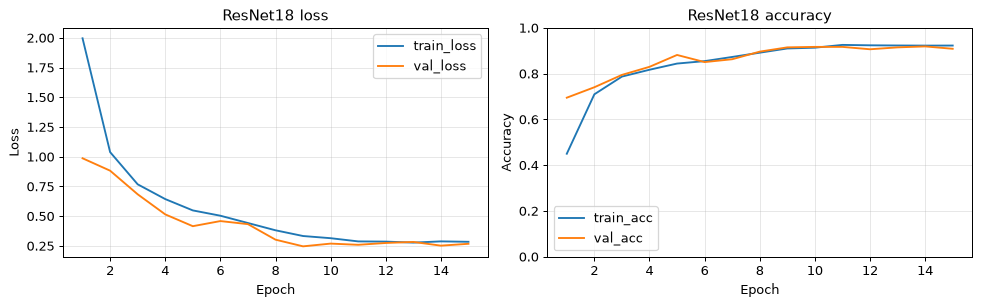

In [62]:
model18 = make_model("resnet18")
model18, hist18 = train_epochs(model18, loaders["train"], loaders["val"],
                               epochs=EPOCHS, lr=1e-4, wd=1e-4, step_size=7, device=device)
torch.save(model18.state_dict(), os.path.join(SAVE_DIR, "resnet18_round1.pth"))

plot_curves(hist18, "ResNet18")

# start a new training for ResNet50

Epoch  1 | train=1.8805 acc=0.4719 | val=0.9052 acc=0.7448  *best*
Epoch  2 | train=0.9130 acc=0.7395 | val=0.7062 acc=0.8071  *best*
Epoch  3 | train=0.6994 acc=0.8021 | val=0.4361 acc=0.8755  *best*
Epoch  4 | train=0.5631 acc=0.8330 | val=0.3778 acc=0.8880  *best*
Epoch  5 | train=0.4716 acc=0.8642 | val=0.5459 acc=0.8402
Epoch  6 | train=0.4409 acc=0.8709 | val=0.3380 acc=0.9025  *best*
Epoch  7 | train=0.4158 acc=0.8735 | val=0.2995 acc=0.9129  *best*
Epoch  8 | train=0.3065 acc=0.9086 | val=0.3113 acc=0.9066
Epoch  9 | train=0.2386 acc=0.9340 | val=0.2801 acc=0.9212  *best*
Epoch 10 | train=0.2350 acc=0.9343 | val=0.2508 acc=0.9191
Epoch 11 | train=0.2252 acc=0.9345 | val=0.2747 acc=0.9108
Epoch 12 | train=0.2152 acc=0.9379 | val=0.2721 acc=0.9170
Epoch 13 | train=0.2081 acc=0.9421 | val=0.2389 acc=0.9295  *best*
Epoch 14 | train=0.2107 acc=0.9371 | val=0.2546 acc=0.9295
Epoch 15 | train=0.2084 acc=0.9449 | val=0.2519 acc=0.9232
Training time: 3.1 min | best val acc: 0.9295


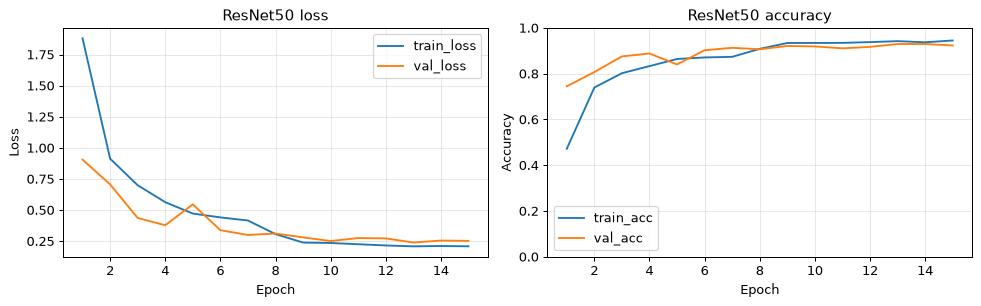

In [63]:
model50 = make_model("resnet50")
model50, hist50 = train_epochs(model50, loaders["train"], loaders["val"],
                               epochs=EPOCHS, lr=1e-4, wd=1e-4, step_size=7, device=device)
torch.save(model50.state_dict(), os.path.join(SAVE_DIR, "resnet50_round1.pth")) 

plot_curves(hist50, "ResNet50")

**Training observations**
- **Cleaned data:** training accuracy reaches ~100 % by epoch 3–5 while validation accuracy levels off at ~92–94 %
  → the models memorise the training set (overfitting).
- **Augmented data:** training accuracy stays at ~92–94 %, close to validation accuracy → much less overfitting.
  The best epochs were late (13–14), so longer training could still help.
- ResNet50 was better on validation in both setups (cleaned 93.78 % vs 92.53 %, augmented 92.95 % vs 91.91 %).
- Training time on an RTX 4070 Laptop GPU (15 epochs): ResNet18 ~1.4 min, ResNet50 ~3.1 min.

# Load Trained Models

- Load saved cleaned and augmented ResNet18 / ResNet50 weights
- Use trained models without repeating training
- Prepare models for final testing

In [64]:
def load_model(name, file):
    model = make_model(name)
    model.load_state_dict(torch.load(os.path.join(SAVE_DIR, file), map_location=device, weights_only=True))
    return model.eval()

model18_clean = load_model("resnet18", "resnet18_clean.pth")
model50_clean = load_model("resnet50", "resnet50_clean.pth")
model18 = load_model("resnet18", "resnet18_round1.pth")
model50 = load_model("resnet50", "resnet50_round1.pth")
print("Models loaded successfully")

Models loaded successfully


## 8. Testing on the test set
The test set (10 %, 472 images) was not used during training or model selection.
Precision, recall and F1 are **macro averages** (computed per species, then averaged).

In [65]:
test_model(model18_clean, "ResNet18 clean", loaders_clean["test"])
test_model(model50_clean, "ResNet50 clean", loaders_clean["test"])
test_model(model18, "ResNet18", loaders["test"])
test_model(model50, "ResNet50", loaders["test"])

ResNet18 clean | accuracy 0.8877 | precision 0.9058 | recall 0.8930 | F1 0.8929
ResNet50 clean | accuracy 0.9089 | precision 0.9203 | recall 0.9146 | F1 0.9147
ResNet18     | accuracy 0.8814 | precision 0.9053 | recall 0.8898 | F1 0.8922
ResNet50     | accuracy 0.9047 | precision 0.9251 | recall 0.9102 | F1 0.9122


Per-species precision, recall and F1:

In [66]:
for name in ["ResNet18", "ResNet50"]:
    print("=" * 25, name, "=" * 25)
    print(classification_report(results[name]["y_true"], results[name]["y_pred"], labels=range(num_classes), target_names=class_names, digits=3, zero_division=0))

========================= ResNet18 =========================
                                   precision    recall  f1-score   support

                    Acer palmatum      0.947     0.900     0.923        20
                   Cedrus deodara      1.000     1.000     1.000        15
                  Celtis sinensis      0.850     0.739     0.791        23
 Cinnamomum camphora (Linn) Presl      0.824     0.966     0.889        29
            Elaeocarpus decipiens      0.857     0.857     0.857        21
                 Flowering cherry      1.000     0.846     0.917        13
                    Ginkgo biloba      0.767     0.821     0.793        28
          Koelreuteria paniculata      0.897     0.929     0.912        28
             Lagerstroemia indica      1.000     1.000     1.000         8
            Liquidambar formosana      0.938     0.750     0.833        20
            Liriodendron chinense      0.656     0.955     0.778        22
           Magnolia grandiflora L     

### 8b. Cleaned vs. augmented training data
Same models, same split, same training settings (15 epochs, Adam 1e-4, StepLR 7),
and the identical test pipeline (resize 256 + center crop 224).
- **cleaned** — training images: resize 256 + center crop 224 (same every epoch)
- **augmented** — training images: RandomResizedCrop + horizontal flip (different every epoch)

The only difference is augmentation during training.

In [67]:
compare = pd.DataFrame({
    arch: {
        "cleaned acc (%)":   results[f"{arch} clean"]["accuracy"] * 100,
        "augmented acc (%)": results[arch]["accuracy"] * 100,
        "cleaned F1 (%)":    results[f"{arch} clean"]["f1"] * 100,
        "augmented F1 (%)":  results[arch]["f1"] * 100,
    } for arch in ["ResNet18", "ResNet50"]
}).T
compare["acc gain"] = compare["augmented acc (%)"] - compare["cleaned acc (%)"]
compare["F1 gain"]  = compare["augmented F1 (%)"] - compare["cleaned F1 (%)"]
compare.round(2)

,cleaned acc (%),augmented acc (%),cleaned F1 (%),augmented F1 (%),acc gain,F1 gain
ResNet18,88.77,88.14,89.29,89.22,-0.64,-0.07
ResNet50,90.89,90.47,91.47,91.22,-0.42,-0.24


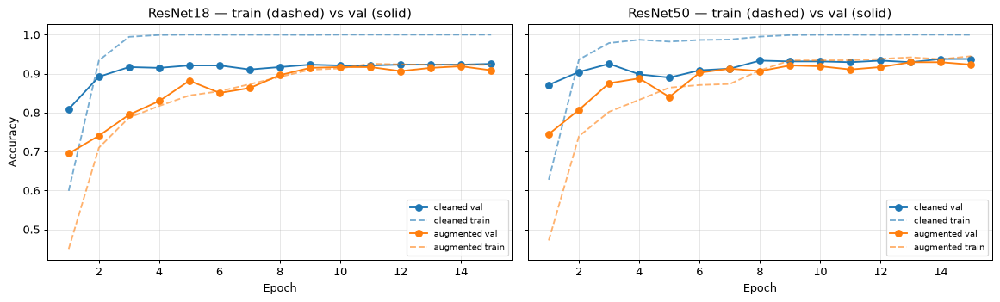

In [68]:
# Solid = validation, dashed = training -> the gap between them shows overfitting
runs = {"ResNet18": {"cleaned": hist18_clean, "augmented": hist18},
        "ResNet50": {"cleaned": hist50_clean, "augmented": hist50}}

fig, axs = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, (arch, hists) in zip(axs, runs.items()):
    for (stage, h), color in zip(hists.items(), ["C0", "C1"]):
        ep = range(1, len(h["val_acc"]) + 1)
        ax.plot(ep, h["val_acc"], color=color, marker="o", label=f"{stage} val")
        ax.plot(ep, h["train_acc"], color=color, ls="--", alpha=0.6, label=f"{stage} train")
    ax.set_title(f"{arch} — train (dashed) vs val (solid)"); ax.set_xlabel("Epoch")
    ax.grid(True, alpha=0.3); ax.legend(fontsize=8)
axs[0].set_ylabel("Accuracy")
plt.tight_layout(); plt.show()

### Confusion matrices
Rows = true species, columns = predicted species. Everything outside the diagonal is an error.

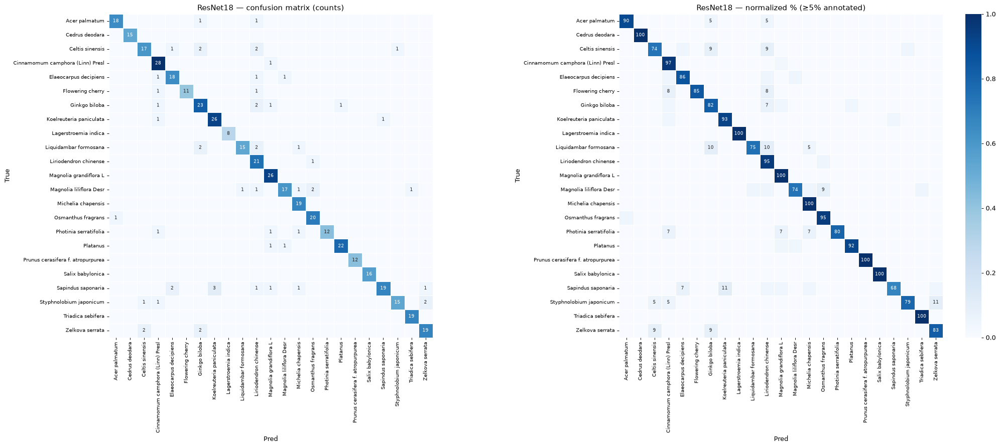

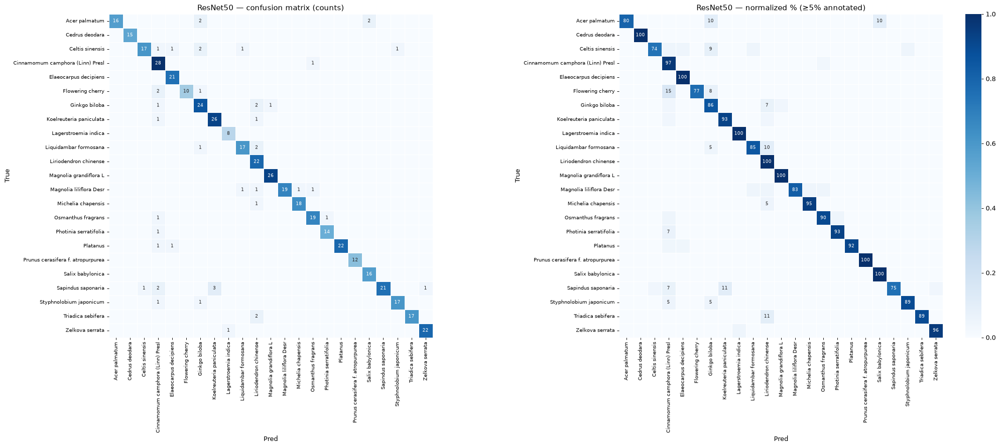

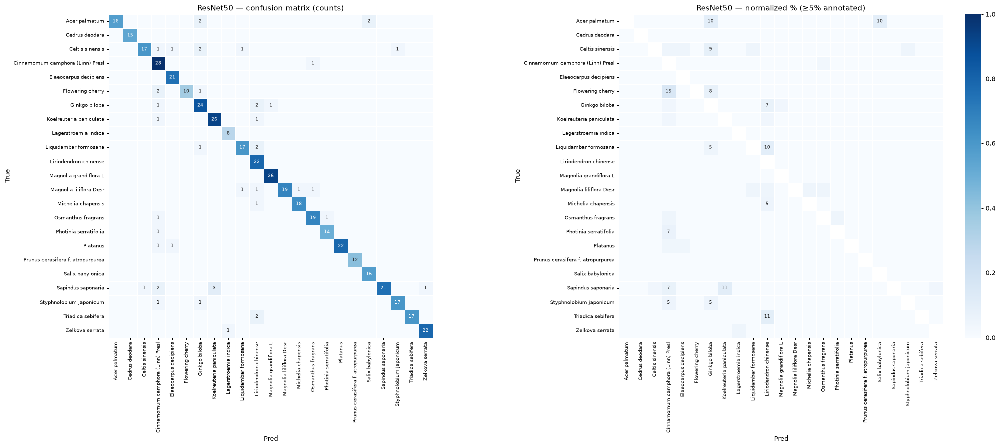

In [69]:
show_confusion_matrices("ResNet18")
show_confusion_matrices("ResNet50")

# Highlight classification errorst
show_confusion_matrices("ResNet50", hide_diag_on_norm=True)

## 9. N-best (top-n) results
A prediction is counted correct if the true species is among the **n most probable** species.
n = 1 is normal accuracy; when n grows, both models go towards 100 %.

**Task:** find the value of n beyond which the n-best results separate (or stop separating) the two models.

The test set has 472 images, so one image ≈ 0.21 %-points. We treat a difference smaller than
**1 %-point** (~5 images) as noise → the models are "not separated" at that n.

In [70]:
MAX_N = 10
ns = list(range(1, MAX_N + 1))

nbest = {name: [top_n_accuracy(results[name]["probs"], results[name]["y_true"], n) for n in ns]
         for name in ["ResNet18", "ResNet50"]}

nbest_df = pd.DataFrame(nbest, index=pd.Index(ns, name="n")) * 100
nbest_df["difference (50 - 18)"] = nbest_df["ResNet50"] - nbest_df["ResNet18"]
nbest_df.round(2)

,ResNet18,ResNet50,difference (50 - 18)
n,,,
1,88.14,90.47,2.33
2,93.22,95.34,2.12
3,95.13,97.03,1.91
4,95.97,98.09,2.12
5,96.82,98.31,1.48
6,97.46,98.52,1.06
7,97.46,98.73,1.27
8,97.46,99.15,1.69
9,98.09,99.36,1.27


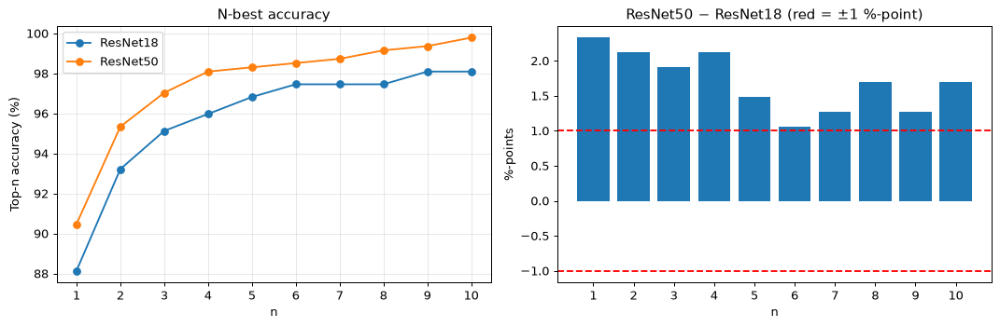

n values where the models differ by at least 1 %-point: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]


In [71]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
for name in ["ResNet18", "ResNet50"]:
    ax1.plot(ns, nbest_df[name], marker="o", label=name)
ax1.set_xlabel("n"); ax1.set_ylabel("Top-n accuracy (%)"); ax1.set_title("N-best accuracy")
ax1.set_xticks(ns); ax1.grid(True, alpha=0.3); ax1.legend()

ax2.bar(ns, nbest_df["difference (50 - 18)"])
ax2.axhline(1, color="red", ls="--"); ax2.axhline(-1, color="red", ls="--")
ax2.set_xlabel("n"); ax2.set_ylabel("%-points"); ax2.set_title("ResNet50 − ResNet18 (red = ±1 %-point)")
ax2.set_xticks(ns)
plt.tight_layout(); plt.show()

separated = [n for n in ns if abs(nbest_df.loc[n, "difference (50 - 18)"]) >= 1.0]
print("n values where the models differ by at least 1 %-point:", separated)

**N-best finding:** At n = 1 ResNet50 is 2.3 %-points better than ResNet18 (90.47 % vs 88.14 %).
The difference shrinks to about 1–1.7 %-points for n ≥ 6, but it stays above the 1 %-point threshold
all the way to n = 10 — so within n ≤ 10 there is no point where n-best stops separating the two models.
At n ≥ 6 the difference is only 5–8 images, so the separation there is weak.

## 10. Error analysis
Which species get mixed up, and what do the wrong images look like?
TIP (from the lecture): look for **systematic** errors — they show dataset challenges or model weaknesses.

In [72]:
most_confused("ResNet18")
most_confused("ResNet50")

--- ResNet18: most common errors (true → predicted) ---
  3   Sapindus saponaria  →  Koelreuteria paniculata
  2   Zelkova serrata  →  Ginkgo biloba
  2   Zelkova serrata  →  Celtis sinensis
  2   Styphnolobium japonicum  →  Zelkova serrata
  2   Sapindus saponaria  →  Elaeocarpus decipiens
  2   Magnolia liliflora Desr  →  Osmanthus fragrans
  2   Liquidambar formosana  →  Liriodendron chinense
  2   Liquidambar formosana  →  Ginkgo biloba
  2   Ginkgo biloba  →  Liriodendron chinense
  2   Celtis sinensis  →  Liriodendron chinense
--- ResNet50: most common errors (true → predicted) ---
  3   Sapindus saponaria  →  Koelreuteria paniculata
  2   Triadica sebifera  →  Liriodendron chinense
  2   Sapindus saponaria  →  Cinnamomum camphora (Linn) Presl
  2   Liquidambar formosana  →  Liriodendron chinense
  2   Ginkgo biloba  →  Liriodendron chinense
  2   Flowering cherry  →  Cinnamomum camphora (Linn) Presl
  2   Celtis sinensis  →  Ginkgo biloba
  2   Acer palmatum  →  Salix babylonica

ResNet50: 45 wrong out of 472 test images


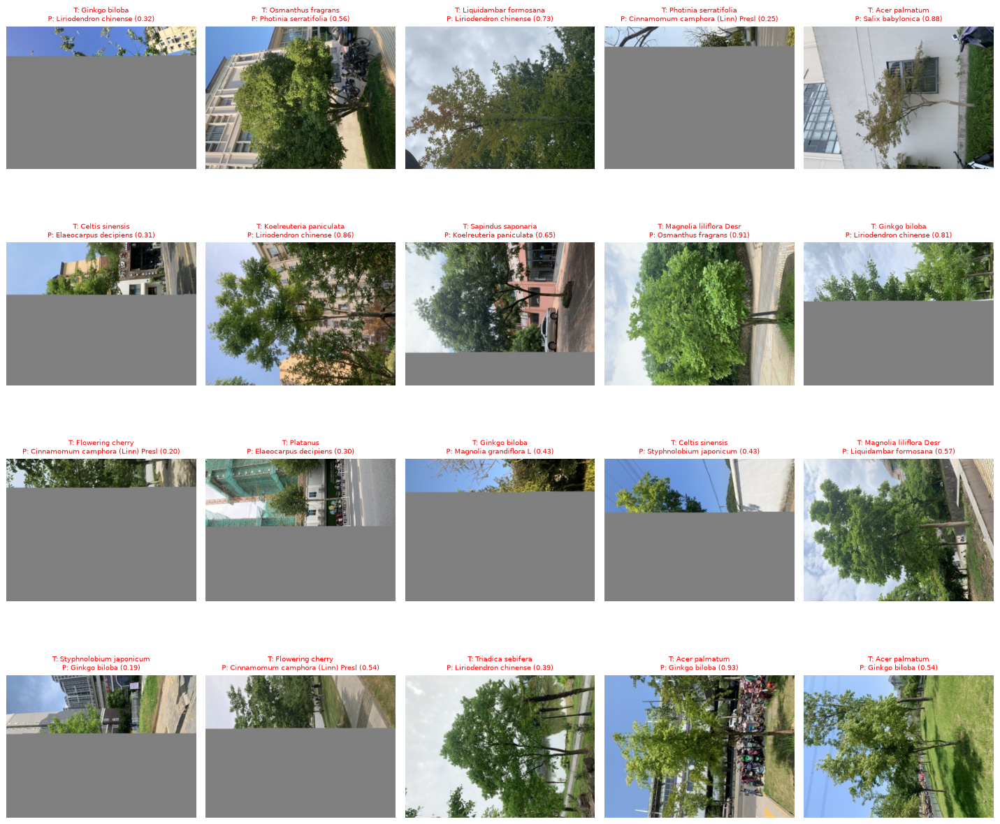

In [73]:
show_misclassified("ResNet50", k=20)

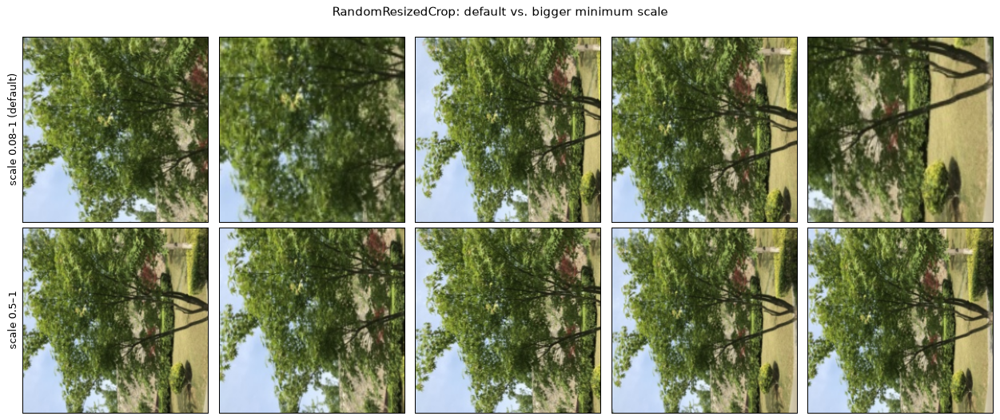

In [74]:
# How much of the tree does RandomResizedCrop keep? Default scale = 8%-100% of the image area.
img = Image.open(train_p[1]).convert("RGB")
fig, axs = plt.subplots(2, 5, figsize=(14, 6))
for j in range(5):
    axs[0, j].imshow(T.RandomResizedCrop(224)(img))
    axs[1, j].imshow(T.RandomResizedCrop(224, scale=(0.5, 1.0))(img))
    axs[0, j].set_xticks([]); axs[0, j].set_yticks([]); axs[1, j].set_xticks([]); axs[1, j].set_yticks([])
axs[0, 0].set_ylabel("scale 0.08–1 (default)"); axs[1, 0].set_ylabel("scale 0.5–1")
plt.suptitle("RandomResizedCrop: default vs. bigger minimum scale"); plt.tight_layout(); plt.show()

**What we noticed** _(edit after looking at your own results)_
- Some species look very similar (same leaf/crown shape) and are confused by **both** models.
- Many errors are **winter** photos (no leaves, only branches) or photos with strong light/shadows.
- The tree is often **small** in the photo, or there are several trees, buildings, cars, people.
  The default `RandomResizedCrop` can cut out a piece with only sky or road, so the model learns from wrong crops.
- Wrong predictions often have low confidence → the right answer is usually in the top-2/top-3 (see n-best).

**Changes for round 2**
1. `RandomResizedCrop(224, scale=(0.5, 1.0))` → crops always contain a big part of the tree
2. `ColorJitter` → robustness to light and season differences
3. small `RandomRotation(10)` → photos are not always straight
4. **label smoothing 0.1** → less over-confident between similar species
5. **20 epochs** (lr step every 8) because the stronger augmentation makes training harder

## 11. Training round 2 — improved models

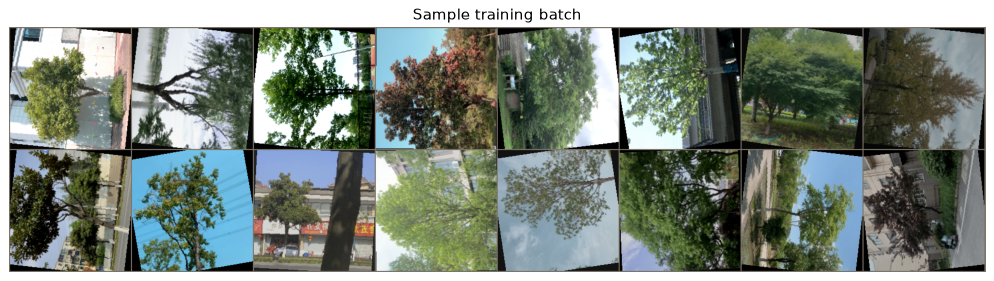

Labels: ['Osmanthus fragrans', 'Salix babylonica', 'Liriodendron chinense', 'Magnolia grandiflora L', 'Sapindus saponaria', 'Platanus', 'Acer palmatum', 'Ginkgo biloba', 'Magnolia grandiflora L', 'Triadica sebifera', 'Magnolia grandiflora L', 'Michelia chapensis', 'Triadica sebifera', 'Sapindus saponaria', 'Sapindus saponaria', 'Prunus cerasifera f. atropurpurea']


In [75]:
train_tfms_v2 = T.Compose([
    T.RandomResizedCrop(224, scale=(0.5, 1.0)),
    T.RandomHorizontalFlip(),
    T.RandomRotation(10),
    T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.05),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

loaders_v2 = make_loaders(train_tfms_v2)   # val/test unchanged -> results are comparable
EPOCHS_V2 = 20

show_batch(loaders_v2["train"])

### 11.1 ResNet18 v2

Epoch  1 | train=2.2069 acc=0.4387 | val=1.4771 acc=0.6826  *best*
Epoch  2 | train=1.3785 acc=0.7460 | val=1.2519 acc=0.7676  *best*
Epoch  3 | train=1.1558 acc=0.8200 | val=1.1523 acc=0.8112  *best*
Epoch  4 | train=1.0340 acc=0.8769 | val=1.0877 acc=0.8444  *best*
Epoch  5 | train=0.9483 acc=0.9091 | val=1.1201 acc=0.8320
Epoch  6 | train=0.9120 acc=0.9236 | val=0.9889 acc=0.8755  *best*
Epoch  7 | train=0.8669 acc=0.9442 | val=0.9611 acc=0.8838  *best*
Epoch  8 | train=0.8349 acc=0.9548 | val=0.9758 acc=0.9046  *best*
Epoch  9 | train=0.7847 acc=0.9758 | val=0.9185 acc=0.9108  *best*
Epoch 10 | train=0.7803 acc=0.9727 | val=0.9199 acc=0.9129  *best*
Epoch 11 | train=0.7595 acc=0.9823 | val=0.9101 acc=0.9149  *best*
Epoch 12 | train=0.7592 acc=0.9826 | val=0.9163 acc=0.9191  *best*
Epoch 13 | train=0.7585 acc=0.9826 | val=0.9155 acc=0.9149
Epoch 14 | train=0.7545 acc=0.9857 | val=0.9043 acc=0.9087
Epoch 15 | train=0.7502 acc=0.9842 | val=0.9153 acc=0.9108
Epoch 16 | train=0.7405 acc

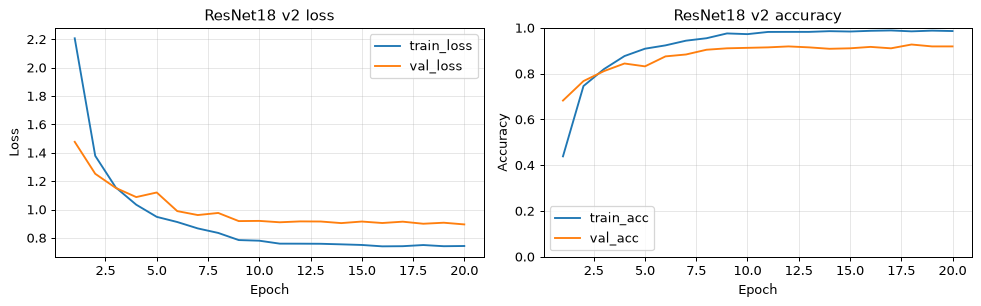

In [76]:
model18_v2 = make_model("resnet18")
model18_v2, hist18_v2 = train_epochs(model18_v2, loaders_v2["train"], loaders_v2["val"], epochs=EPOCHS_V2,
                                     lr=1e-4, wd=1e-4, step_size=8, label_smoothing=0.1, device=device)
torch.save(model18_v2.state_dict(), os.path.join(SAVE_DIR, "resnet18_round2.pth"))
plot_curves(hist18_v2, "ResNet18 v2")

### 11.2 ResNet50 v2

Epoch  1 | train=2.0905 acc=0.4862 | val=1.3537 acc=0.7344  *best*
Epoch  2 | train=1.2910 acc=0.7631 | val=1.2240 acc=0.7801  *best*
Epoch  3 | train=1.0695 acc=0.8548 | val=1.0427 acc=0.8610  *best*
Epoch  4 | train=0.9794 acc=0.8896 | val=1.0196 acc=0.8631  *best*
Epoch  5 | train=0.8976 acc=0.9283 | val=0.9757 acc=0.8942  *best*
Epoch  6 | train=0.8459 acc=0.9436 | val=1.0005 acc=0.8755
Epoch  7 | train=0.8271 acc=0.9491 | val=0.9813 acc=0.8838
Epoch  8 | train=0.8084 acc=0.9538 | val=0.9618 acc=0.8963  *best*
Epoch  9 | train=0.7513 acc=0.9758 | val=0.8935 acc=0.9066  *best*
Epoch 10 | train=0.7267 acc=0.9855 | val=0.8627 acc=0.9149  *best*
Epoch 11 | train=0.7167 acc=0.9891 | val=0.8595 acc=0.9274  *best*
Epoch 12 | train=0.7170 acc=0.9868 | val=0.8518 acc=0.9295  *best*
Epoch 13 | train=0.7092 acc=0.9901 | val=0.8441 acc=0.9315  *best*
Epoch 14 | train=0.7041 acc=0.9904 | val=0.8407 acc=0.9336  *best*
Epoch 15 | train=0.7021 acc=0.9906 | val=0.8468 acc=0.9253
Epoch 16 | train=0.

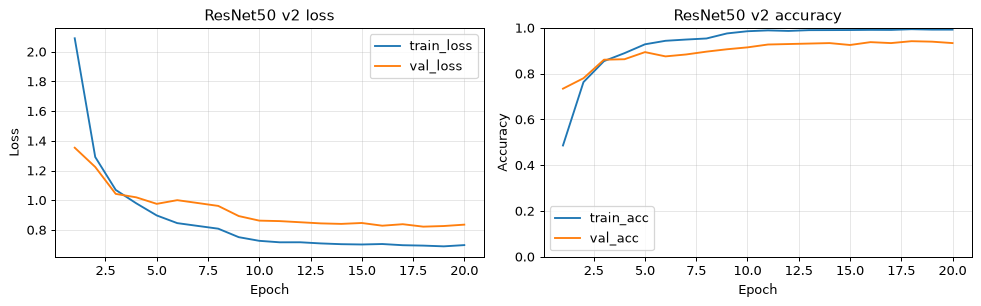

In [77]:
model50_v2 = make_model("resnet50")
model50_v2, hist50_v2 = train_epochs(model50_v2, loaders_v2["train"], loaders_v2["val"], epochs=EPOCHS_V2,
                                     lr=1e-4, wd=1e-4, step_size=8, label_smoothing=0.1, device=device)
torch.save(model50_v2.state_dict(), os.path.join(SAVE_DIR, "resnet50_round2.pth"))
plot_curves(hist50_v2, "ResNet50 v2")

### 11.3 Test results of the improved models

In [78]:
test_model(model18_v2, "ResNet18 v2", loaders_v2["test"])
test_model(model50_v2, "ResNet50 v2", loaders_v2["test"])

ResNet18 v2  | accuracy 0.8517 | precision 0.8735 | recall 0.8653 | F1 0.8615
ResNet50 v2  | accuracy 0.8983 | precision 0.9100 | recall 0.9055 | F1 0.9043


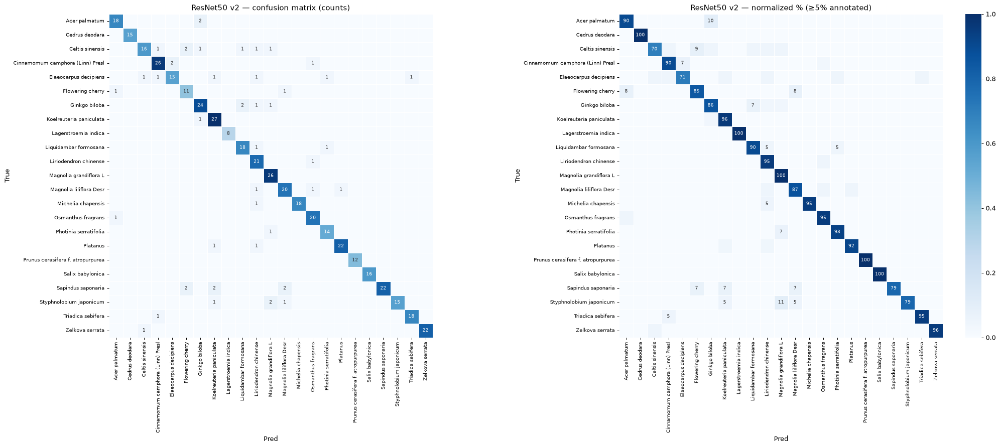

--- ResNet50 v2: most common errors (true → predicted) ---
  2   Styphnolobium japonicum  →  Magnolia grandiflora L
  2   Sapindus saponaria  →  Magnolia liliflora Desr
  2   Sapindus saponaria  →  Koelreuteria paniculata
  2   Sapindus saponaria  →  Flowering cherry
  2   Ginkgo biloba  →  Liquidambar formosana
  2   Cinnamomum camphora (Linn) Presl  →  Elaeocarpus decipiens
  2   Celtis sinensis  →  Flowering cherry
  2   Acer palmatum  →  Ginkgo biloba
  1   Zelkova serrata  →  Celtis sinensis
  1   Triadica sebifera  →  Cinnamomum camphora (Linn) Presl


In [79]:
show_confusion_matrices("ResNet50 v2")
most_confused("ResNet50 v2")

## 12. Final comparison

In [80]:
summary = pd.DataFrame({name: {k: r[k] for k in ["accuracy", "precision", "recall", "f1"]}
                        for name, r in results.items()}).T
summary.round(4)

,accuracy,precision,recall,f1
ResNet18 clean,0.8877,0.9058,0.8930,0.8929
ResNet50 clean,0.9089,0.9203,0.9146,0.9147
ResNet18,0.8814,0.9053,0.8898,0.8922
ResNet50,0.9047,0.9251,0.9102,0.9122
ResNet18 v2,0.8517,0.8735,0.8653,0.8615
ResNet50 v2,0.8983,0.9100,0.9055,0.9043


### Model Comparison

**Key findings**
- All models were tested on the same 472 test images (dataset's own split). One image ≈ 0.21 %-points;
  differences under ~2 %-points are within run-to-run noise.
- **ResNet50 was better than ResNet18 in every setup** (+2.1, +2.3 and +4.7 %-points).
- **Cleaned vs. augmented training data: no significant difference** (ResNet18 88.77 % vs 88.14 %,
  ResNet50 90.89 % vs 90.47 %). Augmentation clearly reduced overfitting (train accuracy ~93 % instead of 100 %)
  but did not improve test accuracy within 15 epochs.
- **Round 2 (stronger augmentation + label smoothing) was worse**, especially for ResNet18 (85.17 %).
- Best test accuracy: **ResNet50 cleaned, 90.89 % (F1 91.47 %)**; ResNet50 augmented is equal within noise
  (90.47 %) and has the best Top-3 / Top-5 accuracy (97.03 % / 98.31 %).

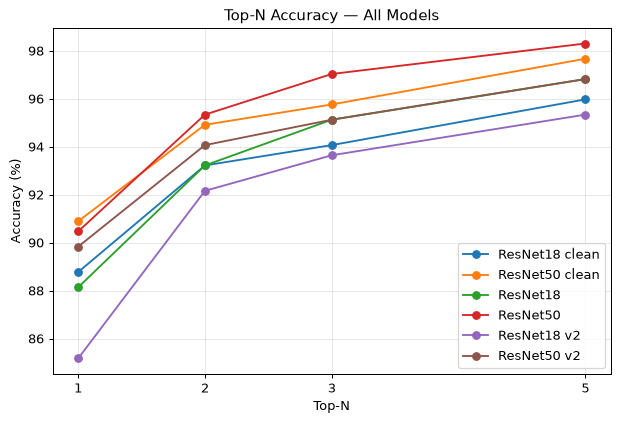

,ResNet18 clean,ResNet50 clean,ResNet18,ResNet50,ResNet18 v2,ResNet50 v2
n,,,,,,
1,88.77,90.89,88.14,90.47,85.17,89.83
2,93.22,94.92,93.22,95.34,92.16,94.07
3,94.07,95.76,95.13,97.03,93.64,95.13
5,95.97,97.67,96.82,98.31,95.34,96.82


In [81]:
# Top-N accuracy for all models
ns = [1, 2, 3, 5]
all_names = list(results.keys())

nbest_all = pd.DataFrame({
    name: [
        top_n_accuracy(results[name]["probs"], results[name]["y_true"], n) * 100
        for n in ns
    ]
    for name in all_names
}, index=pd.Index(ns, name="n"))

# Plot results
plt.figure(figsize=(8, 5))

for name in all_names:
    plt.plot(ns, nbest_all[name], marker="o", label=name)

plt.xlabel("Top-N")
plt.ylabel("Accuracy (%)")
plt.title("Top-N Accuracy — All Models")
plt.xticks(ns)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

# Display comparison table
nbest_all.round(2)

## Conclusions

**Setup**
- 23 urban tree species, 4,804 images, dataset's own stratified split: 3,850 train / 482 val / 472 test.
- Pretrained ResNet18 and ResNet50 (ImageNet), fully fine-tuned with Adam (1e-4), StepLR, batch size 32,
  mixed precision (bf16) on an RTX 4070 Laptop GPU. Training time: ResNet18 ~1.5 min, ResNet50 ~3–4 min (15 epochs).

**Results**

| Model | Training data | Test accuracy | Macro F1 |
|---|---|---|---|
| ResNet18 | cleaned | 88.77 % | 89.29 % |
| ResNet50 | cleaned | **90.89 %** | **91.47 %** |
| ResNet18 | augmented | 88.14 % | 89.22 % |
| ResNet50 | augmented | 90.47 % | 91.22 % |
| ResNet18 | stronger augmentation (round 2) | 85.17 % | 86.15 % |
| ResNet50 | stronger augmentation (round 2) | 89.83 % | 90.43 % |

**What we learned**
- **Model size matters more than augmentation here:** ResNet50 beat ResNet18 in every setup.
- **Augmentation reduced overfitting but did not raise test accuracy.** Without augmentation the models
  memorise the training set (100 % train accuracy by epoch 3–5), yet test accuracy stayed the same.
- **Validation accuracy overestimated test accuracy by 2–7 %-points**, because the best epoch is picked
  on a small validation set (482 images). Round 2 had the best validation scores but not the best test scores.
- **Top-N:** ResNet50 has the correct species in its top 3 for 97 % of test images. The gap to ResNet18
  shrinks from 2.3 %-points (n = 1) to ~1–1.7 %-points (n ≥ 6) but stays above 1 %-point up to n = 10.
- **Hardest species:** *Sapindus saponaria*, most often confused with *Koelreuteria paniculata* —
  both belong to the soapberry family (Sapindaceae). *Liriodendron chinense* is a frequent wrong prediction.
  Visually distinctive species (*Cedrus deodara*, *Salix babylonica*, *Prunus cerasifera* f. *atropurpurea*) are
  recognised almost perfectly.

**Dataset observations**
- The dataset contains duplicate photos: 10 validation images have an exact copy in the training set
  (none in the test set).
- About 78 % of the photos are stored sideways (tree top pointing left). Because of this, `RandomHorizontalFlip`
  turns most trees upside down instead of mirroring them — a likely reason why augmentation did not help.
- About 2 % of the photos (107) are partly damaged (large flat grey areas).

**Final result**
- Best model: **ResNet50, 90.89 % test accuracy, macro F1 91.47 %** (cleaned training data);
  the augmented ResNet50 is equal within noise.

**Possible improvements**
- Rotate the sideways photos upright and use flips that match the real tree orientation.
- Remove damaged and duplicate images.
- Train the augmented models longer (their best epochs were 13–14 of 15).
- Repeat each run with several seeds to separate real differences from noise.
- Try larger input images or newer architectures (e.g. EfficientNet, ConvNeXt).

Trained models (not included in the zip): _(Google Drive link here)_